# idb

Liest die Messwerte aus dem ThingSpeak-Channel, wandelt sie in ein pandas-DataFrame um und stellt sie grafisch dar.

In [ ]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CHANNEL_ID = 3538442
READ_API_KEY = "NXUN4XLS5QB4DFSR"
RESULTS = 8000  # Anzahl Einträge, max. 8000 pro Abfrage

## Daten abrufen

In [ ]:
url = f"https://api.thingspeak.com/channels/{CHANNEL_ID}/feeds.json"

# ThingSpeak liefert pro Abfrage max. 8000 Einträge (die neuesten vor "end").
# Darum rückwärts blättern: nach jeder Abfrage "end" knapp vor den
# ältesten erhaltenen Eintrag setzen, bis weniger als 8000 zurückkommen.
all_feeds = []
end = None

while True:
    params = {"api_key": READ_API_KEY, "results": RESULTS, "timezone": "UTC"}
    if end is not None:
        params["end"] = end.strftime("%Y-%m-%d %H:%M:%S")

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    data = response.json()

    batch = data["feeds"]
    if not batch:
        break

    all_feeds = batch + all_feeds
    print(f"{len(batch)} Einträge geladen, ältester: {batch[0]['created_at']}")

    if len(batch) < RESULTS:
        break  # keine älteren Daten mehr

    oldest = pd.to_datetime(batch[0]["created_at"])
    end = oldest - pd.Timedelta(seconds=1)

channel = data["channel"]

# Doppelte Einträge (falls Grenzen überlappen) entfernen
feeds = list({f["entry_id"]: f for f in all_feeds}.values())
feeds.sort(key=lambda f: f["entry_id"])

print(f"Channel: {channel['name']}  |  {len(feeds)} Einträge total "
      f"(laut Channel: {channel['last_entry_id']})")

8000 Eintraege geladen, aeltester: 2026-10-30T05:35:32Z
6466 Eintraege geladen, aeltester: 2026-10-20T19:52:58Z
Channel: idb_  |  14466 Einträge total (laut Channel: 14466)


## In ein DataFrame umwandeln

- Zeitstempel in Schweizer Zeit umrechnen und als Index setzen
- Werte von Text in Zahlen umwandeln (ThingSpeak liefert alles als Text)
- Spalten `field1`, `field2` ... nach den Feldnamen im Channel benennen

In [11]:
df = pd.DataFrame(feeds)

df["created_at"] = pd.to_datetime(df["created_at"]).dt.tz_convert("Europe/Zurich")
df = df.set_index("created_at").drop(columns=["entry_id"])

df = df.apply(pd.to_numeric, errors="coerce")

field_names = {key: value for key, value in channel.items() if key.startswith("field")}
df = df.rename(columns=field_names)

df.tail()

,Temperatur [°C],Feuchte [%],Licht [%],CO2 [ppm],Staub [pcs/0.01cf],Person (0/1),Alarm (0/1/2/3)
created_at,,,,,,,
2026-11-10 09:31:48+01:00,24.0,46,61.1,806,1.0,0,0
2026-11-10 09:33:48+01:00,24.0,46,61.0,802,1.0,0,0
2026-11-10 09:35:48+01:00,24.0,46,61.0,799,1.0,0,0
2026-11-10 09:37:48+01:00,24.1,46,59.7,804,140.0,0,0
2026-11-10 09:39:49+01:00,24.1,46,51.2,808,114.0,0,0


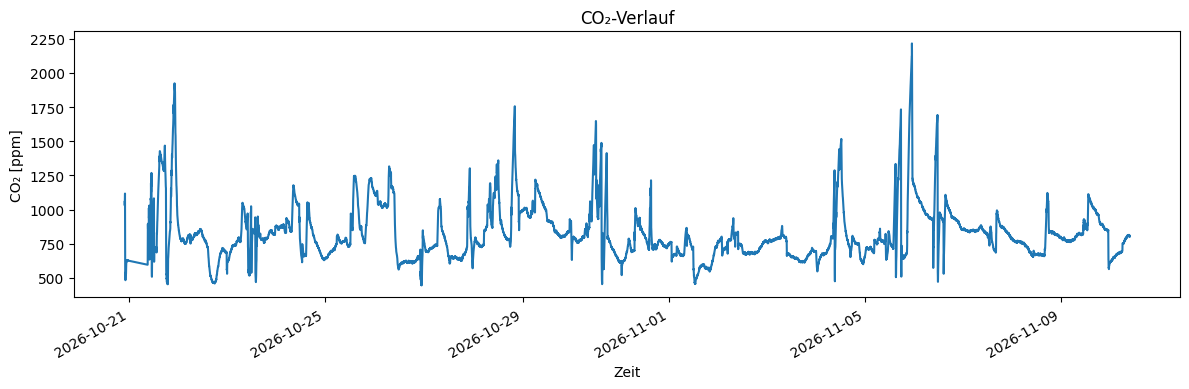

In [12]:
df["CO2 [ppm]"].plot(figsize=(12, 4), title="CO₂-Verlauf")
plt.xlabel("Zeit")
plt.ylabel("CO₂ [ppm]")
plt.grid(False)
plt.tight_layout()
plt.show()

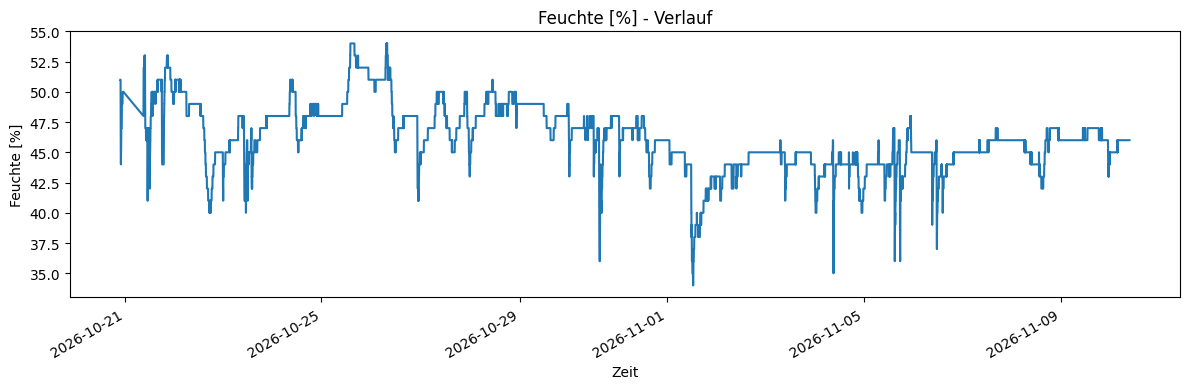

In [13]:
df["Feuchte [%]"].plot(figsize=(12, 4), title="Feuchte [%] - Verlauf")
plt.xlabel("Zeit")
plt.ylabel("Feuchte [%]")
plt.grid(False)
plt.tight_layout()
plt.show()

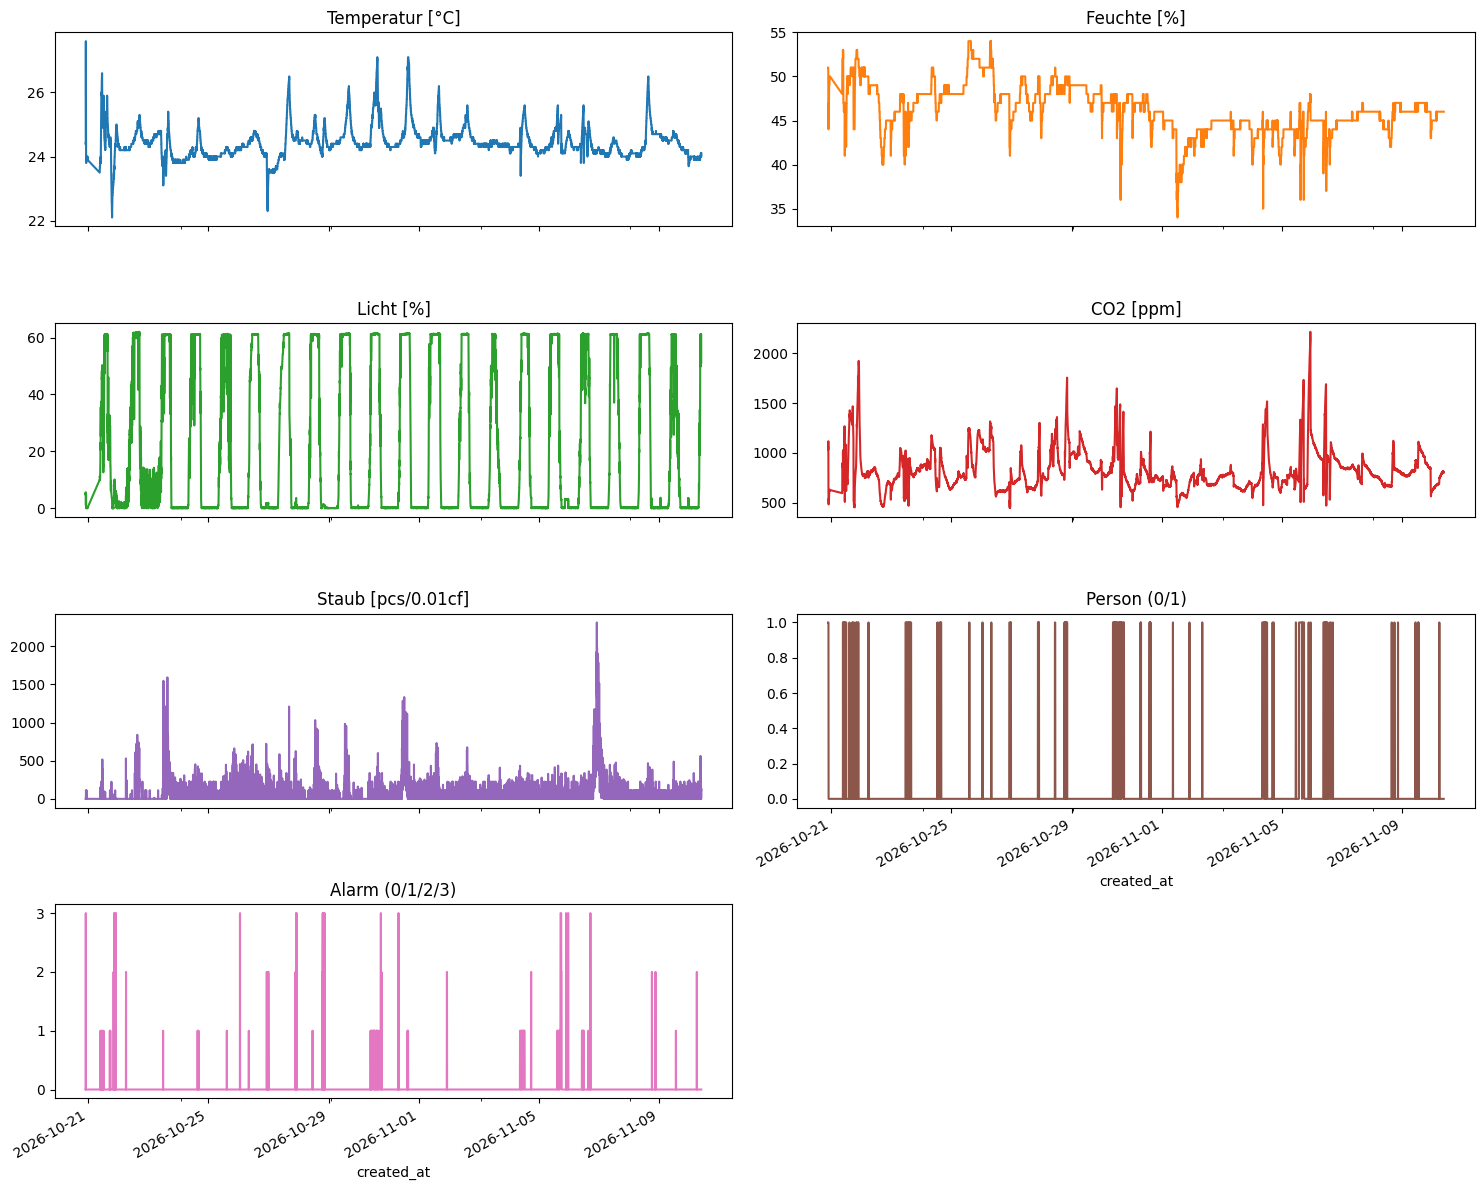

In [14]:
axes = df.plot(
    subplots=True,
    layout=(4, 2),
    figsize=(15, 12),
    sharex=True,
    legend=False
)

for ax, column in zip(axes.flatten(), df.columns):
    ax.set_title(column)

axes[-1, -1].set_visible(False)  # Hide the unused subplot

plt.tight_layout()
plt.show()

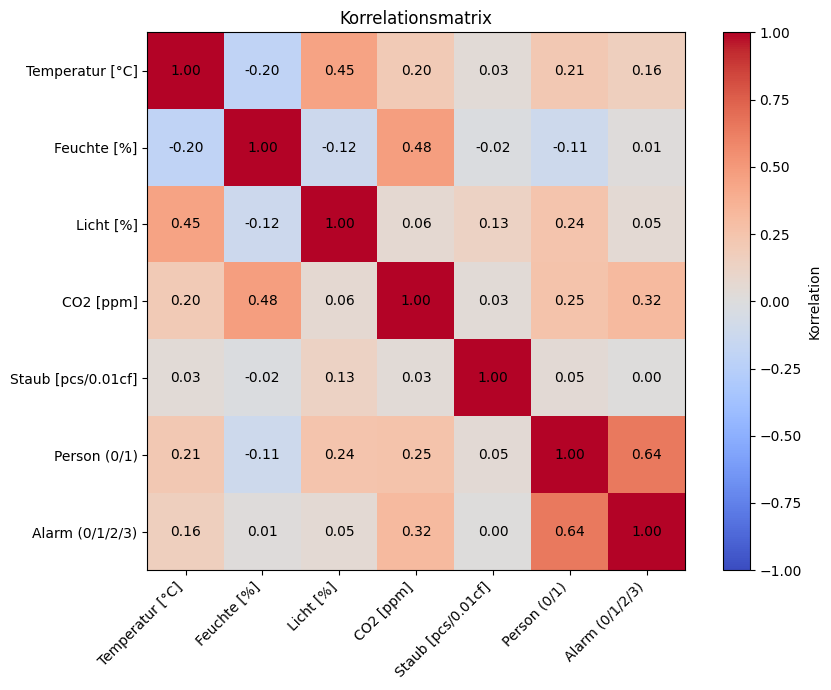

In [15]:
corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

fig.colorbar(image, ax=ax, label="Korrelation")
ax.set_title("Korrelationsmatrix")
plt.tight_layout()
plt.show()

## Kreuzkorrelation (CCF) der Änderungen

Die Korrelationsmatrix vergleicht absolute Werte. Diese werden von Tagesgängen und langsamen Trends dominiert. Für die Frage „Was passiert, wenn das Fenster aufgeht?“ sind die **Änderungen** (Differenzen von Messung zu Messung) aussagekräftiger.

Die CCF zeigt die Korrelation bei verschiedenen Zeitversätzen (Lags). Ein Peak bei Lag 0 bedeutet: Beide Grössen ändern sich gleichzeitig. Ein Peak bei einem positiven Lag bedeutet: Die zweite Grösse reagiert verzögert.

In [ ]:
import numpy as np

cols = ["Temperatur [°C]", "Feuchte [%]", "CO2 [ppm]"]

# Regelmässiges 2-Minuten-Raster, kurze Lücken (bis 10 min) interpolieren
ts = df[cols].resample("2min").mean().interpolate(limit=5)

# Änderungen statt absoluter Werte: entfernt Tages- und Langzeittrends
d = ts.diff()


def ccf(x, y, max_lag):
    """Korrelation von x(t) mit y(t + lag), lag = -max_lag .. +max_lag."""
    lags = np.arange(-max_lag, max_lag + 1)
    return pd.Series([x.corr(y.shift(-lag)) for lag in lags], index=lags)


max_lag = 30  # 30 x 2 min = ±60 min
pairs = [
    ("CO2 [ppm]", "Temperatur [°C]"),
    ("CO2 [ppm]", "Feuchte [%]"),
    ("Temperatur [°C]", "Feuchte [%]"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
conf = 1.96 / np.sqrt(d.dropna().shape[0])  # 95%-Band für "keine Korrelation"

for ax, (a, b) in zip(axes, pairs):
    r = ccf(d[a], d[b], max_lag)
    ax.bar(r.index * 2, r.values, width=1.5)
    ax.axhspan(-conf, conf, color="grey", alpha=0.3)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_title(f"Δ{a.split()[0]} vs. Δ{b.split()[0]}")
    ax.set_xlabel("Lag [min] (positiv: 2. Grösse reagiert später)")
axes[0].set_ylabel("Korrelation")
plt.tight_layout()
plt.show()

## Fensteröffnungen erkennen (Ereignisanalyse)

Fensteröffnungen sind seltene Ereignisse. In der CCF über den ganzen Zeitraum gehen sie im Rauschen unter. Darum werden sie hier direkt gesucht und der Verlauf rund um jede Öffnung übereinandergelegt.

In der Tabelle siehst du pro Öffnung, wie stark sich die Feuchte verändert hat. So lässt sich mit Regen- oder Trockentagen vergleichen.

In [ ]:
# Fenster-auf-Ereignisse finden: CO2 UND Temperatur fallen innerhalb von 10 min deutlich
# Schwellwerte bei Bedarf anpassen
window = 5             # 5 x 2 min = 10 min
CO2_DROP = -100        # ppm
TEMP_DROP = -0.5       # °C

d10 = ts.diff(window)
is_event = (d10["CO2 [ppm]"] < CO2_DROP) & (d10["Temperatur [°C]"] < TEMP_DROP)

# Pro Ereignis nur den ersten Treffer behalten (mind. 60 min Abstand)
event_times = []
for t in ts.index[is_event]:
    if not event_times or t - event_times[-1] > pd.Timedelta("60min"):
        event_times.append(t)

# Änderung über 30 min ab Beginn der Öffnung
d30 = ts.shift(-15) - ts
events = d30.loc[[t - pd.Timedelta(minutes=2 * window) for t in event_times]]
events.columns = [f"Δ30min {c}" for c in cols]
print(f"{len(events)} Fensteröffnungen erkannt")
events.round(1)

In [ ]:
# Durchschnittlicher Verlauf rund um eine Fensteröffnung
before, after = 15, 45  # Schritte à 2 min -> 30 min vorher, 90 min nachher
minutes = np.arange(-before, after + 1) * 2

profiles = {c: [] for c in cols}
for t in event_times:
    i = ts.index.get_loc(t) - window  # ungefährer Beginn der Öffnung
    if i - before < 0 or i + after >= len(ts):
        continue
    seg = ts.iloc[i - before : i + after + 1]
    for c in cols:
        profiles[c].append(seg[c].values - seg[c].iloc[before])  # relativ zum Start

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, c in zip(axes, cols):
    arr = np.array(profiles[c])
    if len(arr) == 0:
        continue
    for row in arr:
        ax.plot(minutes, row, color="grey", alpha=0.25)
    ax.plot(minutes, np.nanmean(arr, axis=0), color="C0", lw=2, label="Mittelwert")
    ax.axvline(0, color="black", ls="--")
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(f"Δ {c}")
    ax.set_xlabel("Minuten ab Öffnung")
axes[0].legend()
plt.tight_layout()
plt.show()

## Weitere Analysen

- **Tagesmuster:** Wann ist die Luft am schlechtesten?
- **Präsenz:** Wie stark steigt CO2 pro 2 Minuten, wenn eine Person im Raum ist?

In [ ]:
# CO2-Tagesmuster: Stunde x Tag
co2 = ts["CO2 [ppm]"]
pivot = co2.groupby([co2.index.date, co2.index.hour]).mean().unstack()

fig, ax = plt.subplots(figsize=(12, max(3, len(pivot) * 0.3)))
image = ax.imshow(pivot, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.set_xlabel("Stunde")
fig.colorbar(image, ax=ax, label="CO2 [ppm]")
ax.set_title("CO2 nach Tag und Stunde")
plt.tight_layout()
plt.show()

In [ ]:
# Wie schnell steigt CO2, wenn jemand im Raum ist?
person = df["Person (0/1)"].resample("2min").max()
dco2 = ts["CO2 [ppm]"].diff()

presence = pd.DataFrame({"Person": person, "ΔCO2 pro 2 min": dco2}).dropna()
print(presence.groupby("Person")["ΔCO2 pro 2 min"].describe())

presence.boxplot(column="ΔCO2 pro 2 min", by="Person", showfliers=False, figsize=(6, 4))
plt.suptitle("")
plt.title("CO2-Änderung mit / ohne Person")
plt.tight_layout()
plt.show()

## Korrelation der Änderungen und Einfluss der Anwesenheit

- Korrelation der Rohwerte im Vergleich zu den Änderungen über 2, 10 und 30 Minuten
- Änderungen über 10 Minuten, getrennt nach Anwesenheit (Bewegungsmelder)

In [ ]:
# Korrelation der Änderungen über verschiedene Zeitfenster
print("Rohwerte")
print(ts.corr().round(2), "\n")

for steps in [1, 5, 15]:  # 2, 10, 30 Minuten
    print(f"Änderung über {steps * 2} min")
    print(ts.diff(steps).corr().round(2), "\n")

In [ ]:
# 10-Minuten-Änderungen, gekoppelt mit Anwesenheit
steps = 5  # 5 x 2 min = 10 min
person = df["Person (0/1)"].resample("2min").max()
present = person.rolling(steps).max()  # War im 10-min-Fenster jemand im Raum?

d_person = ts.diff(steps).assign(Person=present).dropna()

# 1) Mittlere Änderung mit / ohne Person
print(d_person.groupby("Person")[cols].mean().round(2), "\n")

# 2) Korrelation getrennt nach Person
for p, grp in d_person.groupby("Person"):
    print(f"Person = {int(p)}  (n = {len(grp)})")
    print(grp[cols].corr().round(2), "\n")

## Findings

### 1. Rohwerte korrelieren kaum, Änderungen schon

In der Korrelationsmatrix der Rohwerte liegen Temperatur, Feuchte und CO₂ nahe bei 0. Die Werte werden die meiste Zeit von unterschiedlichen, langsamen Einflüssen bestimmt: CO₂ von der Anwesenheit, die Temperatur von Heizung und Sonne, die Feuchte vom Wetter. Kurze Ereignisse wie eine Fensteröffnung machen nur einen kleinen Teil der Daten aus und gehen darin unter.

Betrachtet man stattdessen die **Änderungen** über ein Zeitfenster, zeigen sich deutliche Zusammenhänge:

| Paar | Rohwerte | 2 min | 10 min | 30 min |
|---|---|---|---|---|
| CO₂ – Feuchte | ≈ 0 | 0.47 | **0.71** | 0.67 |
| CO₂ – Temperatur | ≈ 0 | 0.22 | 0.47 | **0.55** |
| Temperatur – Feuchte | ≈ 0 | 0.03 | 0.23 | 0.30 |

- Bei 2 min ist der Zusammenhang schwach. Messrauschen und die grobe Sensorauflösung (Feuchte in ganzen %, Temperatur in 0.1 °C) überdecken ihn.
- Bei 10 bis 30 min ist er am stärksten. Das entspricht der Dauer von Lüften und Anwesenheit.
- Die Temperatur reagiert träger, ihre Korrelation mit CO₂ ist bei 30 min am höchsten. Nach dem Lüften geben Wände und Möbel Wärme ab.
- Temperatur und Feuchte korrelieren am schwächsten. Wärmere Luft senkt die **relative** Feuchte, das wirkt dem gemeinsamen Abfall beim Lüften entgegen.

### 2. Anwesenheit verstärkt den Zusammenhang

Änderungen über 10 min, getrennt danach, ob der Bewegungsmelder im Fenster eine Person erkannt hat:

| | ohne Person (n = 13055) | mit Person (n = 1185) |
|---|---|---|
| Ø ΔCO₂ / 10 min | −0.88 ppm | **+6.28 ppm** |
| Ø ΔFeuchte / 10 min | +0.01 % | −0.14 % |
| r(CO₂, Feuchte) | 0.51 | **0.83** |
| r(CO₂, Temperatur) | 0.28 | 0.56 |
| r(Temperatur, Feuchte) | 0.05 | 0.37 |

- Mit Person steigt CO₂ deutlich an (Atmung), ohne Person sinkt es langsam.
- Der Zusammenhang zwischen CO₂ und Feuchte ist mit Person deutlich stärker (0.83 statt 0.51). Der Unterschied ist statistisch klar signifikant (Fisher-z-Test, z ≈ 20).
- Die hohe Korrelation mit Person entsteht vermutlich aus zwei Effekten, die in dieselbe Richtung wirken:
  - **Atmung:** CO₂ und Feuchte steigen langsam gemeinsam.
  - **Lüften:** CO₂ und Feuchte fallen schnell gemeinsam. Fenster werden nur geöffnet, wenn jemand im Raum ist.
- Dass die Feuchte mit Person im Mittel leicht *sinkt*, spricht dafür, dass das Lüften in dieser Gruppe einen grossen Anteil hat.
- Auch ohne Person bleibt eine Korrelation von 0.51. Mögliche Gründe sind der langsame Luftaustausch über Türspalten und Undichtigkeiten sowie Zeiten, in denen jemand still sitzt.

### Einschränkungen

- Der PIR-Sensor erkennt **Bewegung**, nicht Anwesenheit. Wer still sitzt, wird als „keine Person“ gemessen. Die Anwesenheit wird also unterschätzt (nur ca. 8 % der Zeit mit Person), und der Unterschied zwischen den Gruppen fällt eher zu klein aus.
- Die 10-min-Fenster überlappen sich, die Messungen sind daher nicht unabhängig. Der z-Wert ist zu hoch angesetzt, der Unterschied bleibt aber auch bei vorsichtiger Schätzung signifikant.
- Die Feuchte ist relativ und hängt selbst von der Temperatur ab.

### Nächster Schritt

Atmung und Lüften trennen: In der Gruppe mit Person die erkannten Fensteröffnungen ausschliessen. Bleibt r(CO₂, Feuchte) hoch, kommt der Zusammenhang von der Atmung. Fällt er stark ab, ist er hauptsächlich vom Lüften getrieben.